# Assignment 1: Simple Linear Regression

<br>

>---
>
>1. Read in the "Computers.csv" file & perform any desired EDA.
>
>2. Fit a regression model with target = "price".  Fit your model on the feature with the strongest correlation to price
>
>
>3. Interpret the model equation
>
>4. Visualize the residuals of your model
>
>5. Make predictions for common values of your feature
>
>---

<br>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# -----------------------------------------------
import statsmodels.api as sm


In [2]:
computers = pd.read_csv("../datasets/Computers.csv")

computers.head()

,price,speed,hd,ram,screen,cd,multi,premium,ads,trend
0,1499,25,80,4,14,no,no,yes,94,1
1,1795,33,85,2,14,no,no,yes,94,1
2,1595,25,170,4,15,no,no,yes,94,1
3,1849,25,170,8,14,no,no,no,94,1
4,3295,33,340,16,14,no,no,yes,94,1


In [3]:
computers.info()

<class 'pandas.DataFrame'>
RangeIndex: 6259 entries, 0 to 6258
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   price    6259 non-null   int64
 1   speed    6259 non-null   int64
 2   hd       6259 non-null   int64
 3   ram      6259 non-null   int64
 4   screen   6259 non-null   int64
 5   cd       6259 non-null   str  
 6   multi    6259 non-null   str  
 7   premium  6259 non-null   str  
 8   ads      6259 non-null   int64
 9   trend    6259 non-null   int64
dtypes: int64(7), str(3)
memory usage: 489.1 KB


<br>

---

### EDA

In [4]:
# Let's see some statistics
computers.describe()

,price,speed,hd,ram,screen,ads,trend
count,6259.000000,6259.000000,6259.000000,6259.000000,6259.000000,6259.000000,6259.000000
mean,2219.576610,52.011024,416.601694,8.286947,14.608723,221.301007,15.926985
std,580.803956,21.157735,258.548445,5.631099,0.905115,74.835284,7.873984
min,949.000000,25.000000,80.000000,2.000000,14.000000,39.000000,1.000000
25%,1794.000000,33.000000,214.000000,4.000000,14.000000,162.500000,10.000000
50%,2144.000000,50.000000,340.000000,8.000000,14.000000,246.000000,16.000000
75%,2595.000000,66.000000,528.000000,8.000000,15.000000,275.000000,21.500000
max,5399.000000,100.000000,2100.000000,32.000000,17.000000,339.000000,35.000000


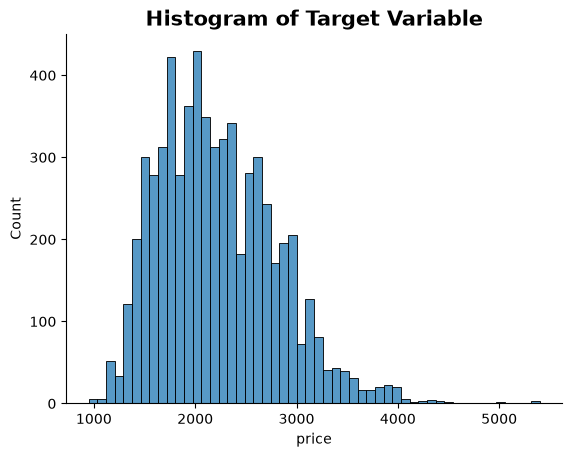

In [5]:
# The distribution of the target
sns.histplot(data=computers, x='price')

plt.title('Histogram of Target Variable', fontsize=15, fontweight='bold')
sns.despine()

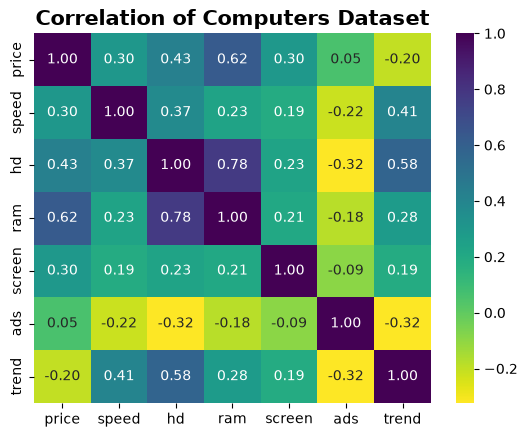

In [6]:
# now let's see the correlation 
sns.heatmap(computers.corr(numeric_only=True),
            annot=True, cmap='viridis_r',
            #vmin=-1, vmax=1,
            fmt='.2f'
           )
plt.title('Correlation of Computers Dataset', fontsize=15, fontweight='bold')
plt.show()

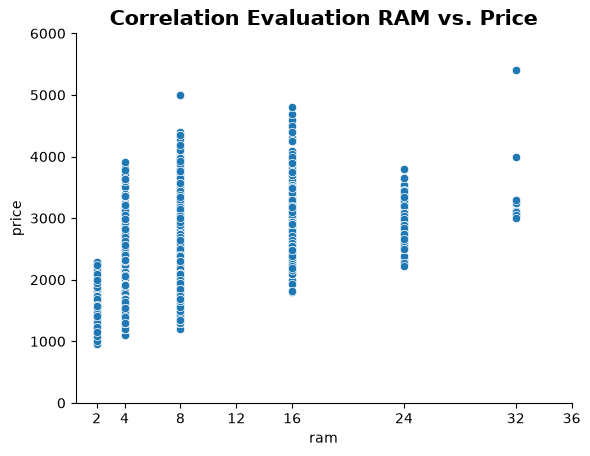

In [7]:
# Since 'ram' has the highest correlation with 'price' will plot it
sns.scatterplot(data=computers, x='ram', y='price')

plt.title('Correlation Evaluation RAM vs. Price', fontsize=15, fontweight='bold')
plt.ylim(0, 6000)
plt.xticks([2, 4, 8, 12, 16, 24, 32, 36])
sns.despine()

<br><br>

---

### Model Fitting

In [8]:
X = sm.add_constant(computers.ram)
y = computers.price

display(X.head())
y.head()

,const,ram
0,1.0,4
1,1.0,2
2,1.0,4
3,1.0,8
4,1.0,16


0    1499
1    1795
2    1595
3    1849
4    3295
Name: price, dtype: int64

In [9]:
model_assign = sm.OLS(y, X).fit()

model_assign.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  price   R-squared:                       0.388
Model:                            OLS   Adj. R-squared:                  0.388
Method:                 Least Squares   F-statistic:                     3964.
Date:                Fri, 06 Nov 2026   Prob (F-statistic):               0.00
Time:                        12:16:02   Log-Likelihood:                -47180.
No. Observations:                6259   AIC:                         9.436e+04
Df Residuals:                    6257   BIC:                         9.438e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       1687.2925     10.221    165.073      0.000    1667.255    1707.330
ram           64.2316      1.020     62.959      0.000      62.232      66.232
==============================================================================
Omnibus:                     1327.783   Durbin-Watson:                   1.533
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             3113.140
Skew:                           1.188   Prob(JB):                         0.00
Kurtosis:                       5.508   Cond. No.                         17.9
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

<br><br>

---

### Intepretation:


<br>

>---
>
>A one megabyte increase in RAM is associated with a $64.23 increase in price.
>
>---

<br><br>

---

### Plot Residuals

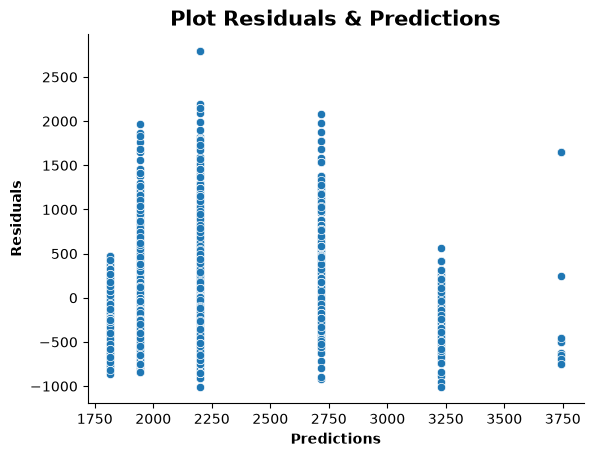

In [10]:
sns.scatterplot(x=model_assign.predict(), y=model_assign.resid)

plt.title('Plot Residuals & Predictions', fontsize=15, fontweight='bold')
plt.xlabel('Predictions', fontweight='bold')
plt.ylabel('Residuals', fontweight='bold')
sns.despine()

<br><br>

---

### Make Predictions with the values below

In [11]:
feature_values = [0, 2, 4, 8, 16, 32, 64]

predicts_df = sm.add_constant(pd.DataFrame({'ram':feature_values}))
predicts_df

,const,ram
0,1.0,0
1,1.0,2
2,1.0,4
3,1.0,8
4,1.0,16
5,1.0,32
6,1.0,64


In [12]:
predictions = model_assign.predict(predicts_df)

predictions.index = feature_values
predictions = predictions.reset_index()
predictions.columns = ['ram', 'predictions']

predictions

,ram,predictions
0,0,1687.292537
1,2,1815.755790
2,4,1944.219043
3,8,2201.145550
4,16,2714.998564
5,32,3742.704591
6,64,5798.116644
